1(b)

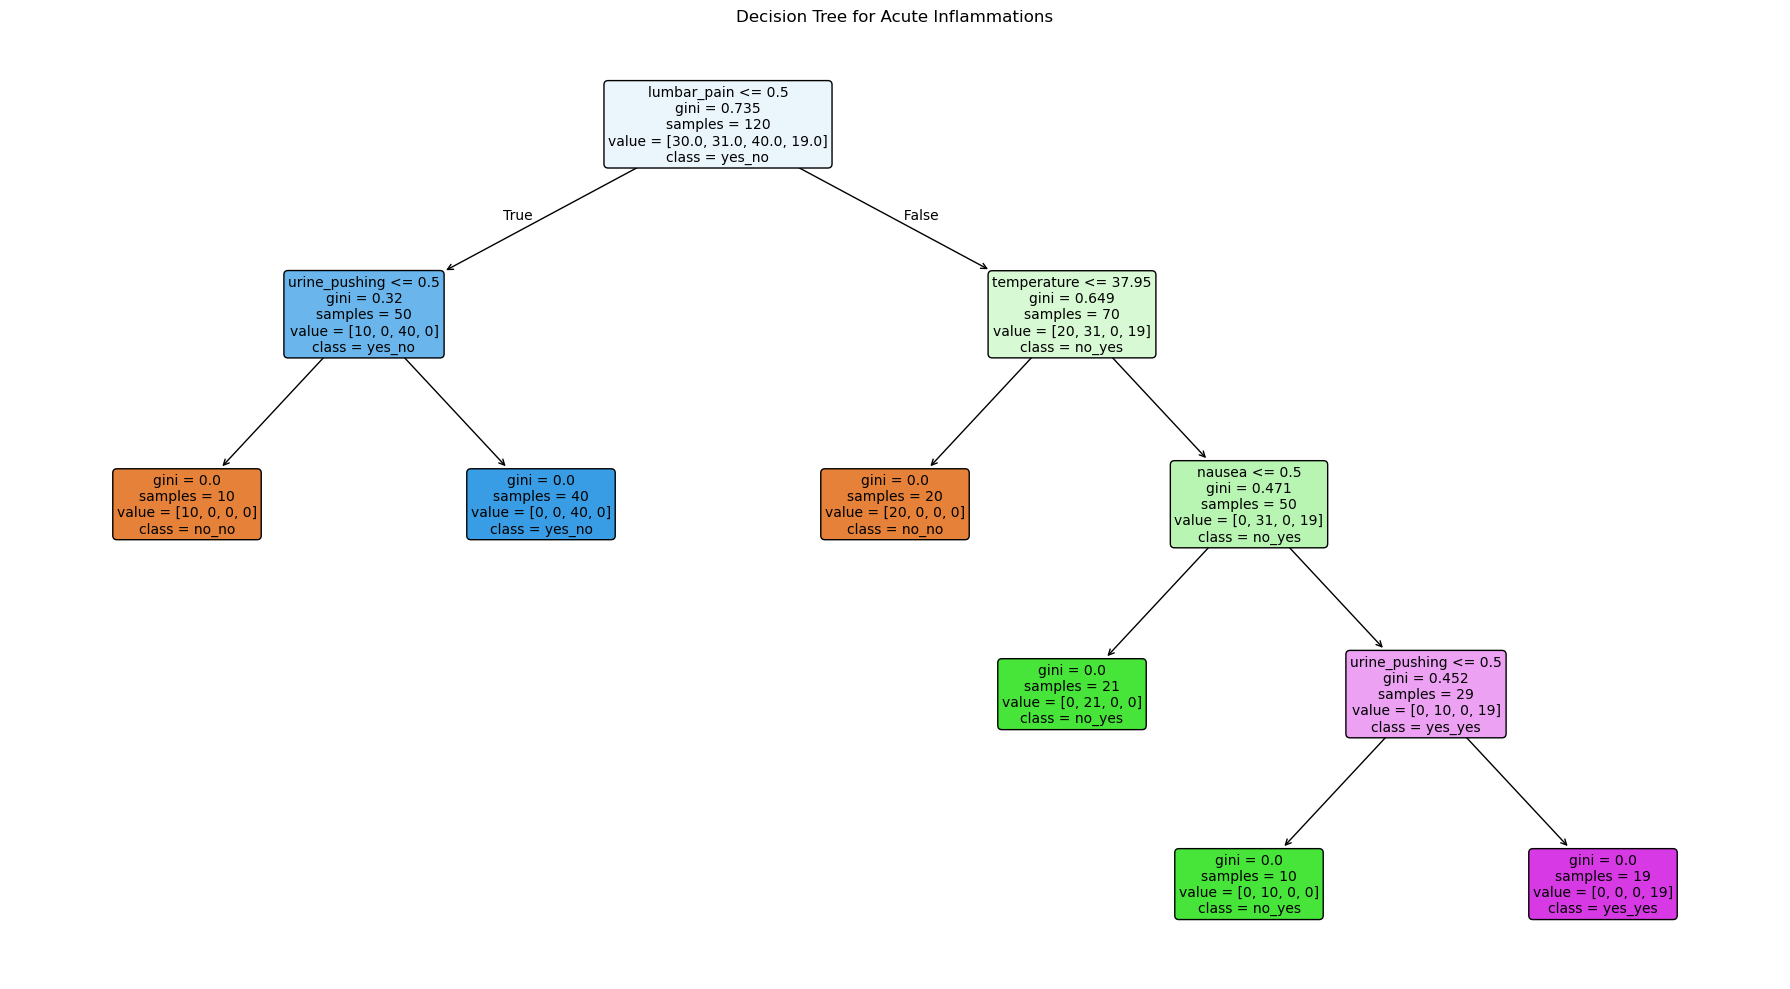

Tree depth: 4
Number of leaves: 6
Training accuracy: 100.00%


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Import the data
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethral_burning",
    "bladder_inflammation",
    "renal_pelvis_nephritis"
]

df = pd.read_csv(
    "../data/Homework 5 Data/diagnosis.data",
    sep="\t",
    encoding="utf-16",
    decimal=",",
    header=None,
    names=columns
)

# Encode the binary features: no = 0, yes = 1
X = df.iloc[:, :6].copy()

for col in X.columns[1:]:
    X[col] = X[col].map({"no": 0, "yes": 1})

# Combine the two labels using the label powerset method
y = df["bladder_inflammation"] + "_" + df["renal_pelvis_nephritis"]

# Decision tree
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)

# Plot the decision tree
plt.figure(figsize=(18, 10))

plot_tree(
    tree_model,
    feature_names=X.columns.tolist(),
    class_names=tree_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())
print(f"Training accuracy: {tree_model.score(X, y):.2%}")

1(c)

In [16]:
def print_rules(model, feature_names):
    tree = model.tree_

    def walk(node, conditions):
        # A leaf node gives the predicted class
        if tree.children_left[node] == -1:
            label = model.classes_[tree.value[node][0].argmax()]
            condition_text = " AND ".join(conditions) or "TRUE"
            print(f"IF {condition_text} THEN class = {label}")

        else:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            # Left branch: condition is true
            walk(
                tree.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )

            # Right branch: condition is false
            walk(
                tree.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )

    walk(0, [])


print_rules(tree_model, X.columns.tolist())

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN class = no_no
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN class = yes_no
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = no_no
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN class = no_yes
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN class = no_yes
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN class = yes_yes


1(d)

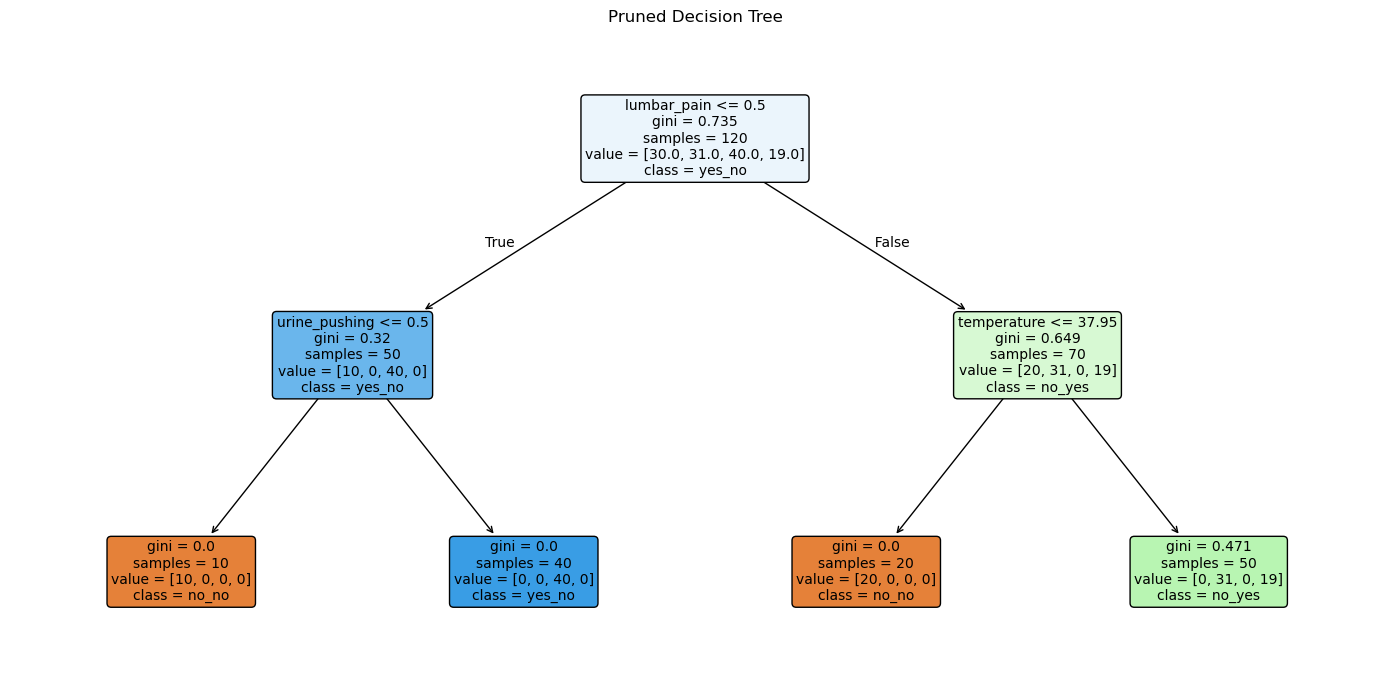

In [17]:
# Apply cost-complexity pruning alpha=0.1
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.1
)
pruned_tree.fit(X, y)

# Plot the pruned tree
plt.figure(figsize=(14, 7))

plot_tree(
    pruned_tree,
    feature_names=X.columns.tolist(),
    class_names=pruned_tree.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.show()


Decision Rules

1. IF the patient has no lumbar pain and no continuous need to urinate, THEN predict neither disease.
2. IF the patient has no lumbar pain but has a continuous need to urinate, THEN predict bladder inflammation only.
3. IF the patient has lumbar pain and a temperature at or below 37.95°C, THEN predict neither disease.
4. IF the patient has lumbar pain and a temperature above 37.95°C, THEN predict nephritis of renal pelvis origin only.

2(a)

In [18]:
import pandas as pd


# Read column names from the dataset description
with open("../data/Homework 5 Data/communities.names", encoding="utf-8") as f:
    columns = [
        line.split()[1]
        for line in f
        if line.lower().startswith("@attribute")
    ]

# Load the dataset; "?" represents missing values
communities = pd.read_csv(
    "../data/Homework 5 Data/communities.data",
    header=None,
    names=columns,
    na_values="?"
)

# Use the first 1495 rows for training and the rest for testing
train_data = communities.iloc[:1495].copy()
test_data = communities.iloc[1495:].copy()

print("Full dataset:", communities.shape)
print("Training set:", train_data.shape)
print("Test set:", test_data.shape)

communities.head()

Full dataset: (1994, 128)
Training set: (1495, 128)
Test set: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


2(b)

The five non-predictive variables—state, county, community, communityname, and fold—were removed, leaving 122 predictors. Missing values were replaced with the median of each feature calculated from the entire dataset.

In [19]:
from sklearn.impute import SimpleImputer

# Remove non-predictive columns and separate the target
non_predictive = [
    "state", "county", "community", "communityname", "fold"
]
target = "ViolentCrimesPerPop"

X = communities.drop(columns=non_predictive + [target])
y = communities[target].copy()

print("Missing values before imputation:", X.isna().sum().sum())

# Fill missing values using medians from the entire dataset
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:", X.isna().sum().sum())

# Split the processed data without shuffling
X_train = X.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()

y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

Missing values before imputation: 36851
Missing values after imputation: 0
Training features: (1495, 122)
Test features: (499, 122)


2(c)

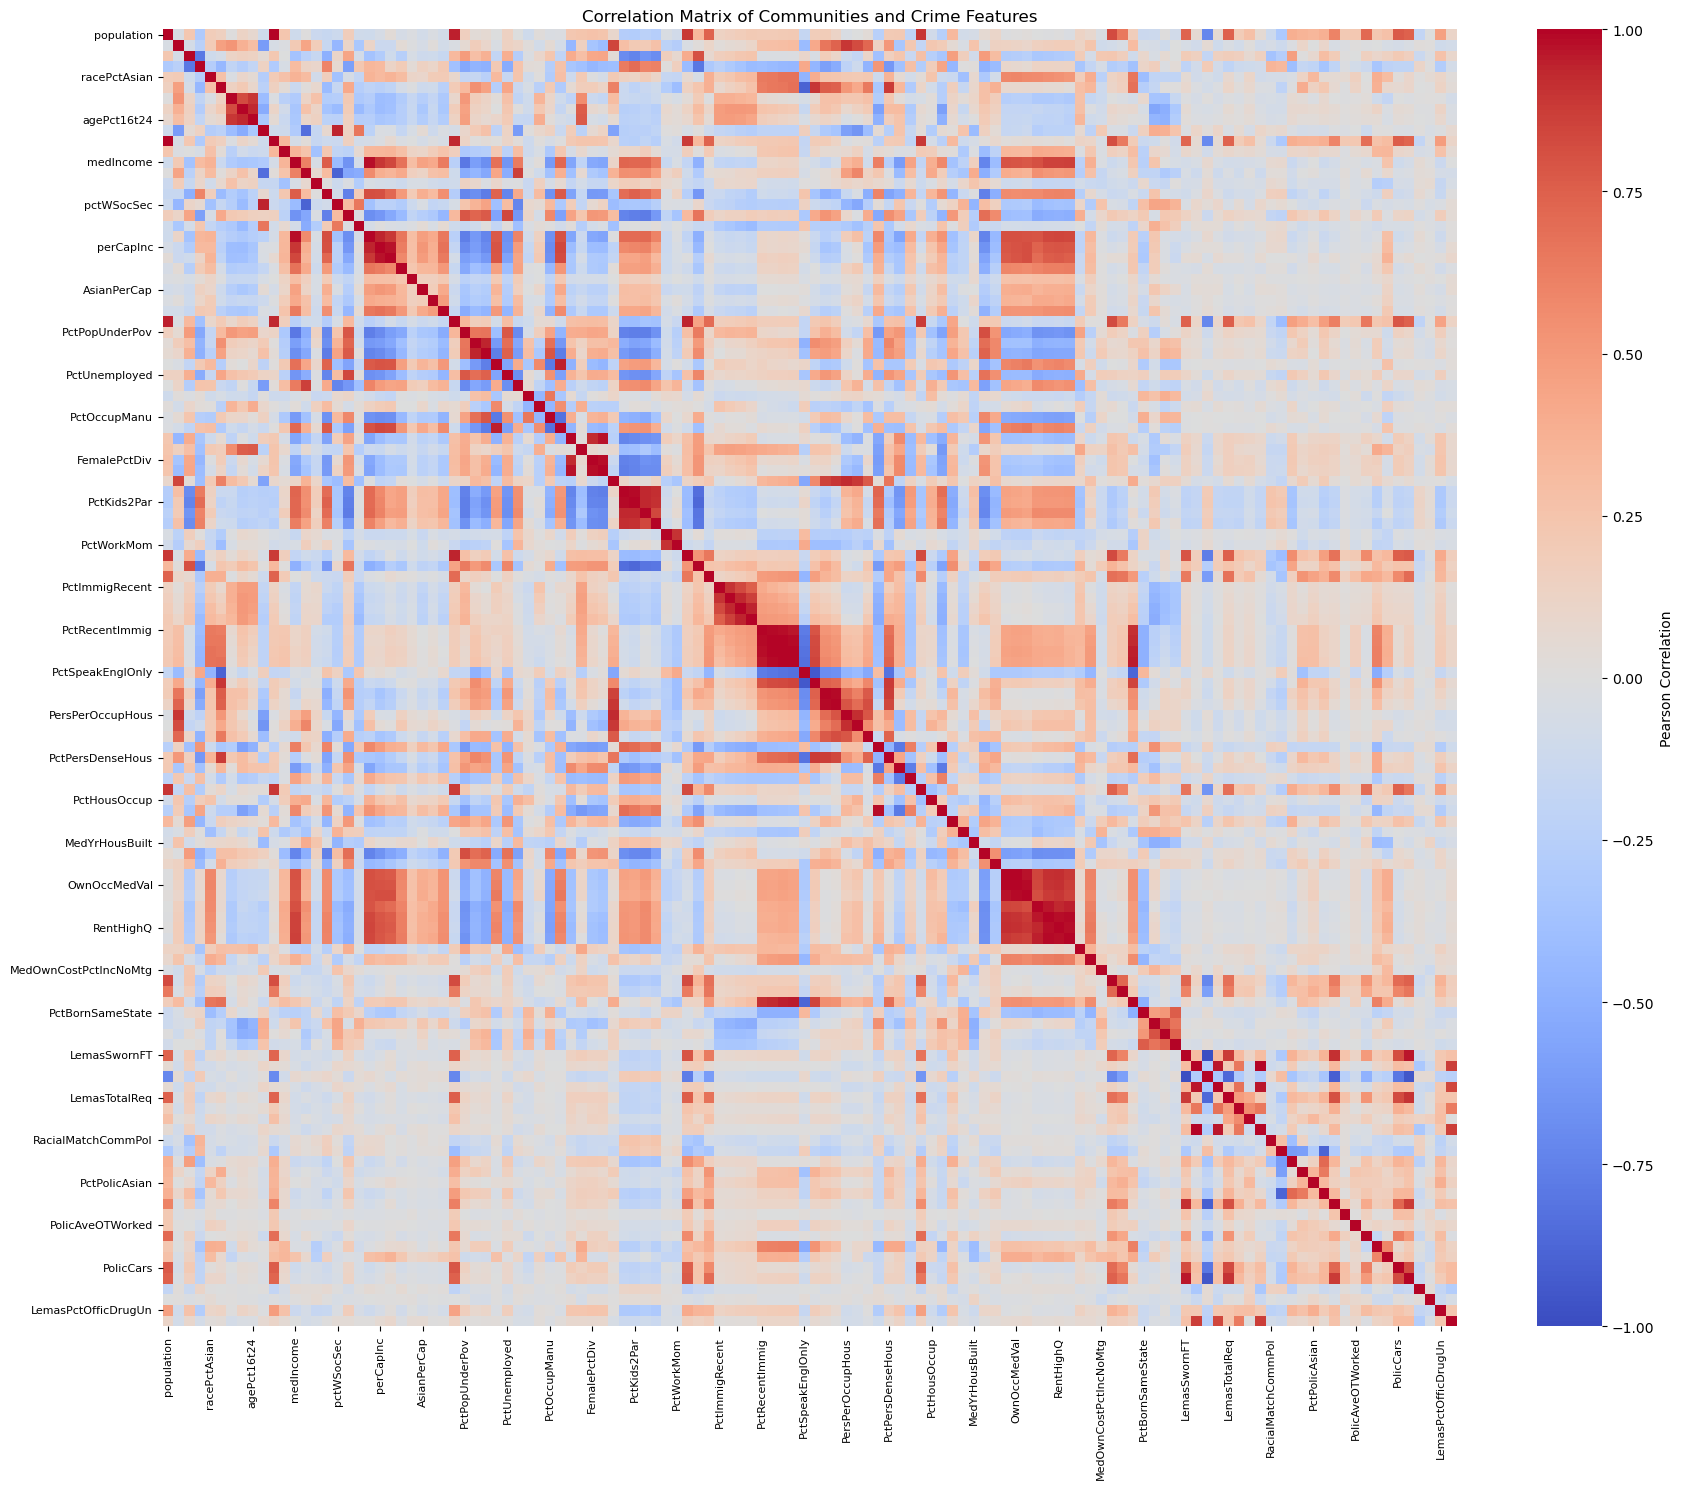

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
correlation_matrix = X.corr()

# Plot the correlation heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    xticklabels=4,
    yticklabels=4,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Matrix of Communities and Crime Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

2(d)

In [21]:
# Calculate the mean and sample standard deviation of each feature
feature_mean = X.mean()
feature_std = X.std(ddof=1)

# Calculate the coefficient of variation
cv = feature_std / feature_mean

# Display results in descending order
cv_table = pd.DataFrame({
    "Mean": feature_mean,
    "Sample SD": feature_std,
    "CV": cv
}).sort_values("CV", ascending=False)

display(cv_table)

,Mean,Sample SD,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
...,...,...,...
NumKindsDrugsSeiz,0.567768,0.081320,0.143227
RacialMatchCommPol,0.731906,0.092479,0.126354
LemasPctPolicOnPatr,0.741775,0.087514,0.117979
PctPolicWhite,0.771515,0.090554,0.117372


2(e)

,Mean,Sample SD,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


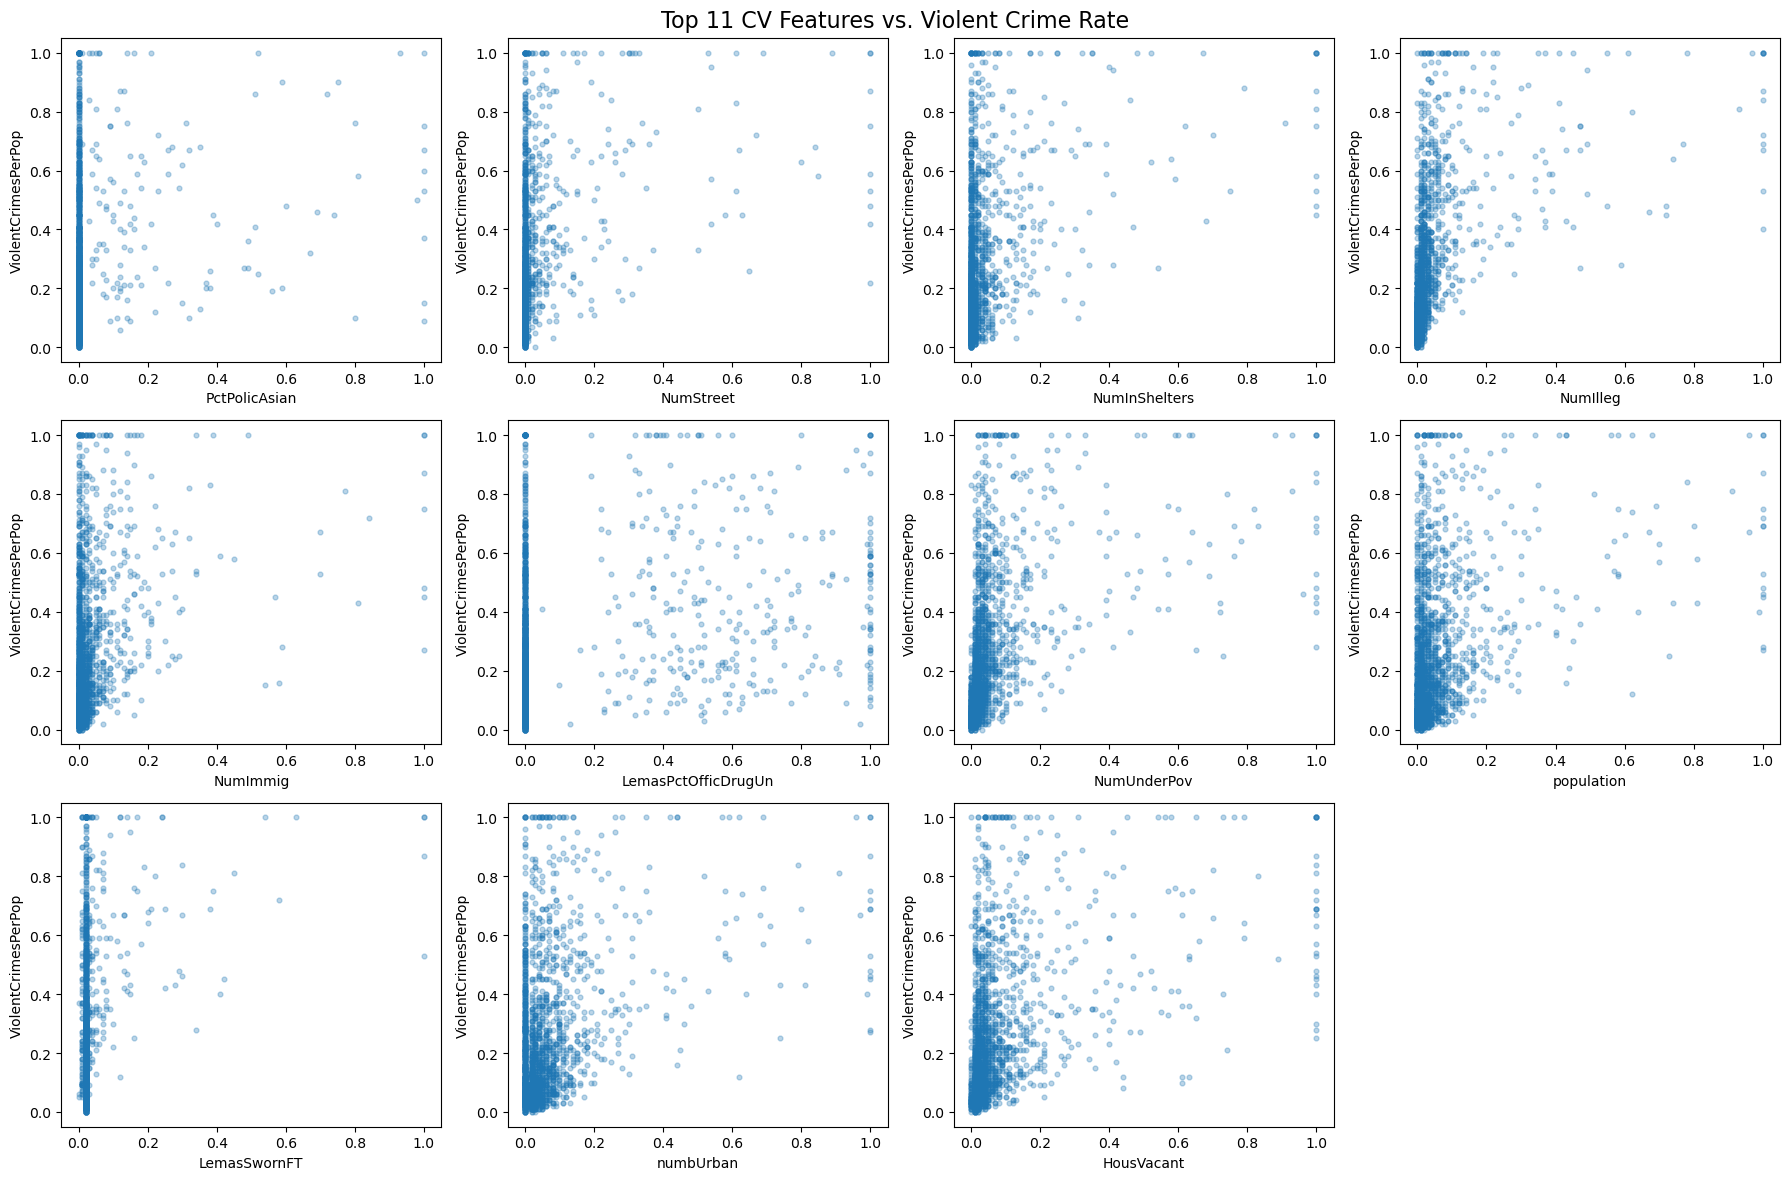

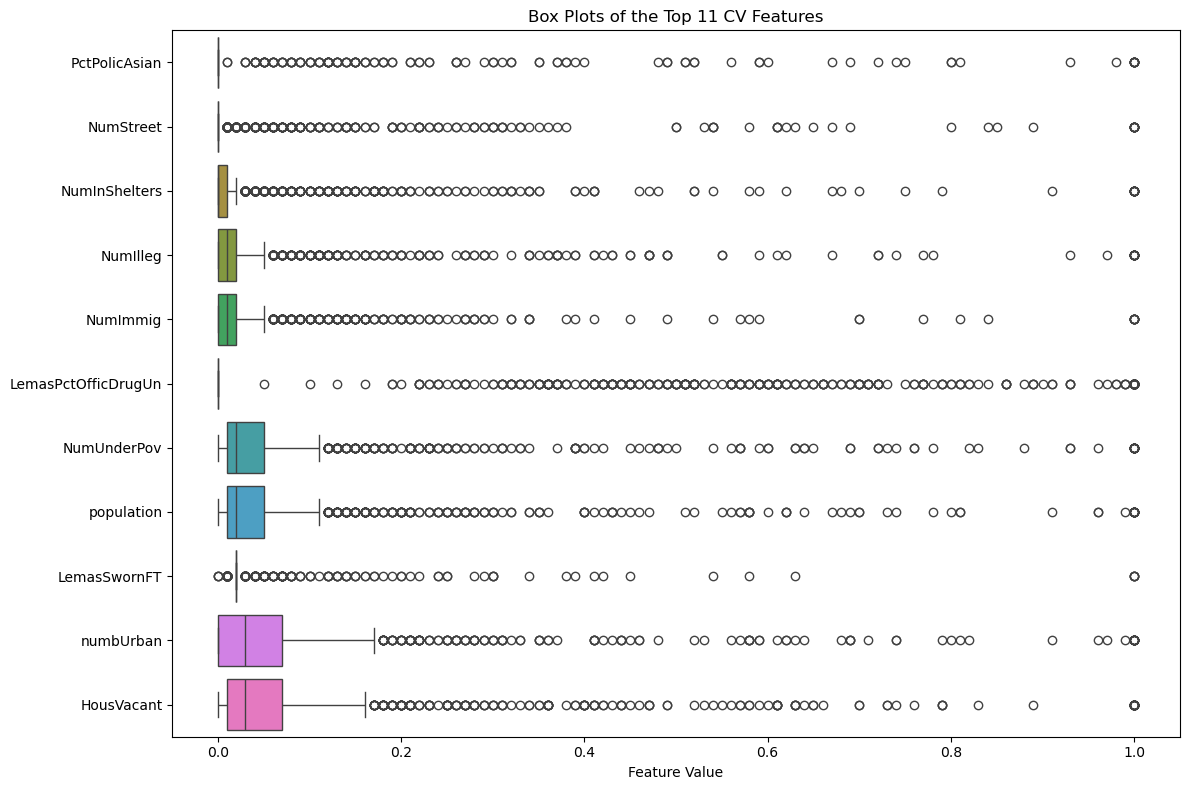

In [22]:
# Select the 11 features with the highest CV
top_features = cv_table.head(11).index.tolist()

display(cv_table.loc[top_features])

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(X[feature], y, alpha=0.3, s=12)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

# Remove the unused subplot
fig.delaxes(axes[-1])

fig.suptitle("Top 11 CV Features vs. Violent Crime Rate", fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=X[top_features],
    orient="h"
)

plt.title("Box Plots of the Top 11 CV Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()

Statistical significance cannot be determined from scatter plots alone. The plots may suggest associations, but they do not account for the effects of other predictors or provide statistical tests. A high CV indicates high variability relative to the mean, not necessarily a strong relationship with the target variable.

2(f) least squares

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Fit an ordinary least squares linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict on the test set
y_pred = linear_model.predict(X_test)

# Calculate the test mean squared error
test_mse = mean_squared_error(y_test, y_pred)

print(f"Test MSE: {test_mse:.6f}")

Test MSE: 0.017977


2(g) ridge regression five-fold cross-validation

In [24]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# Candidate values of lambda
alphas = np.logspace(-4, 4, 100)

# Set up five-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Select lambda using cross-validation and fit ridge regression
ridge_model = RidgeCV(
    alphas=alphas,
    cv=cv,
    scoring="neg_mean_squared_error"
)
ridge_model.fit(X_train, y_train)

# Evaluate on the test set
y_pred_ridge = ridge_model.predict(X_test)
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

print(f"Best lambda: {ridge_model.alpha_:.6f}")
print(f"Test MSE: {ridge_test_mse:.6f}")

Best lambda: 3.351603
Test MSE: 0.017472


2(h) LASSO

In [25]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

# Candidate lambda values and five-fold cross-validation
alphas = np.logspace(-5, 0, 100)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
selected_variables = {}
lasso_models = {}

# Fit LASSO with and without standardization
for name, scaler in [
    ("Original", "passthrough"),
    ("Standardized", StandardScaler())
]:
    pipeline = Pipeline([
        ("scaler", scaler),
        ("lasso", Lasso(max_iter=100000))
    ])

    search = GridSearchCV(
        pipeline,
        param_grid={"lasso__alpha": alphas},
        cv=cv,
        scoring="neg_mean_squared_error"
    )
    search.fit(X_train, y_train)

    # Evaluate the selected model
    best_model = search.best_estimator_
    predictions = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, predictions)

    # Variables with nonzero coefficients are selected
    coefficients = best_model.named_steps["lasso"].coef_
    selected = X_train.columns[coefficients != 0].tolist()

    lasso_models[name] = best_model
    selected_variables[name] = selected

    results.append({
        "Features": name,
        "Best lambda": search.best_params_["lasso__alpha"],
        "Test MSE": test_mse,
        "Selected variables": len(selected)
    })

# Compare model performance
lasso_results = pd.DataFrame(results)
display(lasso_results.round(6))

# List all selected variables for each model
for name, variables in selected_variables.items():
    print(f"\n{name}: {len(variables)} selected variables")
    print(", ".join(variables))

,Features,Best lambda,Test MSE,Selected variables
0,Original,0.000115,0.017638,74
1,Standardized,0.000658,0.017715,75



Original: 74 selected variables
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, Nu

2(i) PCR 5-fold cross-validation to select M

In [26]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

# PCR: standardization, PCA, and linear regression
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])

# Select the number of principal components using five-fold CV
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pcr_search = GridSearchCV(
    pcr_pipeline,
    param_grid={
        "pca__n_components": range(1, X_train.shape[1] + 1)
    },
    cv=cv,
    scoring="neg_mean_squared_error"
)

pcr_search.fit(X_train, y_train)

# Evaluate the selected PCR model on the test set
pcr_model = pcr_search.best_estimator_
y_pred_pcr = pcr_model.predict(X_test)

best_M = pcr_search.best_params_["pca__n_components"]
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)

print("Best M:", best_M)
print(f"Test MSE: {pcr_test_mse:.6f}")

Best M: 60
Test MSE: 0.018335


2(j) XGBoost L1 penalized gradient boosting tree

In [27]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

# Define the boosting tree model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    booster="gbtree",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    reg_lambda=0,       # Disable L2 regularization
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

# Select the L1 regularization parameter using five-fold CV
cv = KFold(n_splits=5, shuffle=True, random_state=42)

xgb_search = GridSearchCV(
    xgb_model,
    param_grid={
        "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]
    },
    cv=cv,
    scoring="neg_mean_squared_error"
)

xgb_search.fit(X_train, y_train)

# Evaluate the selected model on the test set
best_xgb = xgb_search.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)

best_alpha = xgb_search.best_params_["reg_alpha"]
xgb_test_mse = mean_squared_error(y_test, y_pred_xgb)

print("Best alpha:", best_alpha)
print(f"Test MSE: {xgb_test_mse:.6f}")

Best alpha: 1
Test MSE: 0.016666
